# Road Extraction MVP

A minimal pipeline that turns one satellite image into a binary road mask and compares it to the ground truth.

1. Preprocessing RGB → HSV 
2. Histogram equalization CLAHE
3. Edge-preserving smoothing Adaptive median filter
4. Binarization Otsu threshold
5. Shape filtering Morphological opening + closing
6. Line breakage recombination Morphological reconstruction

https://www.kaggle.com/datasets/balraj98/deepglobe-road-extraction-dataset

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.morphology import reconstruction

## Load image and its ground truth
Change `DATA_DIR` to where you unzipped the dataset, and `IMAGE_INDEX` to try a different image.

In [2]:
IMAGE_FILE = "sample_img_2.jpg"
MASK_FILE = "sample_mask_2.png"

bgr = cv2.imread(IMAGE_FILE)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# Ground truth
mask = cv2.imread(MASK_FILE, cv2.IMREAD_GRAYSCALE)
ground_truth = np.where(mask > 128, True, False)

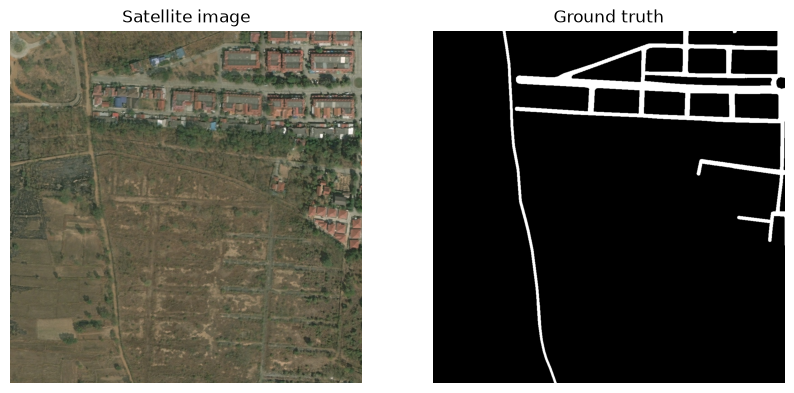

In [3]:
def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.show()


show([rgb, ground_truth], ["Satellite image", "Ground truth"])

## Convert to HSV
HSV separates color (hue, saturation) from brightness (value).
Roads tend to be grey (low saturation), so the channels make them easier to tell apart from vegetation.
We continue the pipeline on the **V (value)** channel.

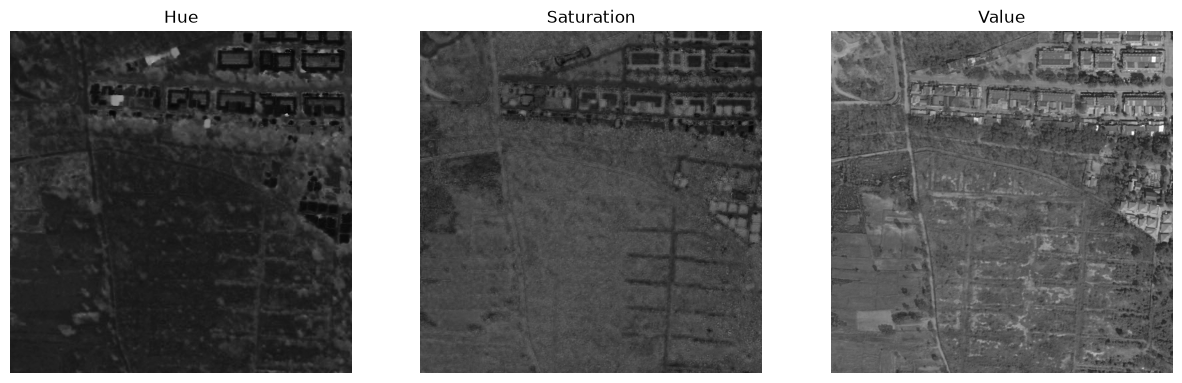

In [4]:
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
hue, saturation, value = cv2.split(hsv)

show([hue, saturation, value], ["Hue", "Saturation", "Value"])

## CLAHE (Contrast Limited Adaptive Histogram Equalization)
https://docs.opencv.org/4.13.0/d5/daf/tutorial_py_histogram_equalization.html

Equalizes the histogram in small tiles, which boosts local contrast without blowing out the whole image.

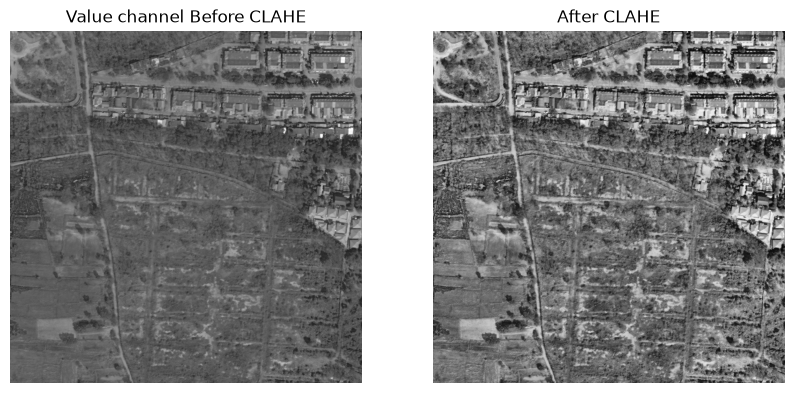

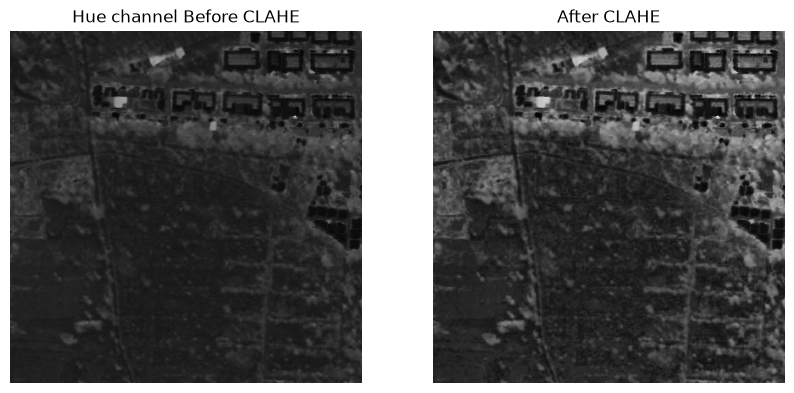

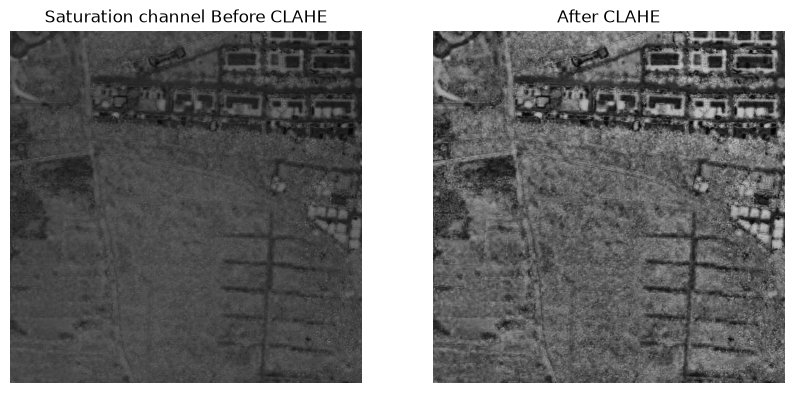

In [5]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
equalized_val = clahe.apply(value)
equalized_hue = clahe.apply(hue)
equalized_sat = clahe.apply(saturation)

show([value, equalized_val], ["Value channel Before CLAHE", "After CLAHE"])
show([hue, equalized_hue], ["Hue channel Before CLAHE", "After CLAHE"])
show([saturation, equalized_sat], ["Saturation channel Before CLAHE", "After CLAHE"])

# equalized_val = value
# equalized_hue = hue
# equalized_sat = saturation


## Adaptive median filter
For each pixel, start with a 3x3 window and grow it (up to `max_size`) until the median is not an extreme value.
Then:
- if the pixel itself is not an extreme value, it is kept (this preserves edges);
- otherwise it is replaced by the median (this removes noise).

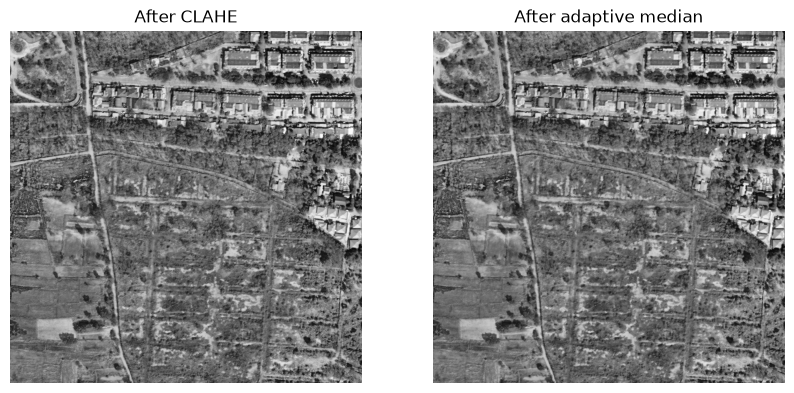

In [6]:
# ref: adaptive_median_filter_HW3
def adaptive_median_filter(img, max_size):
    [height, width] = img.shape
    window_size = 3
    
    done = np.zeros((height, width), dtype='bool')
    output = img.copy()
    weight_matrix = np.zeros((height, width), dtype=int)
    
    while window_size <= max_size:
        kernel_size = (window_size, window_size)
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, kernel_size)
        current_weight_matrix = np.full((height, width), window_size)

        # Break out into min, max, median matrices
        min_matrix = np.where(done, img, cv2.erode(img, kernel))
        max_matrix = np.where(done, img, cv2.dilate(img, kernel))
        median_matrix = np.where(done, img, cv2.medianBlur(img, window_size))

        # since the adaptive median filter, for each kernel size has 2 output types
        # I made a mask which would maintain only the values that had to be output as median
        # and I separated the mask that would keep the values the same
        # but this only matters if the values have not already been changed, so I just compare
        # it against a done matrix which tells the loop if one of the elements has already been
        # worked on.
        median_mask = ((min_matrix < median_matrix) & (median_matrix < max_matrix)) | done
        keep_mask = ((min_matrix < img) & (img < max_matrix)) | done
    
        # put together the new image
        median_result = np.where(~keep_mask, median_matrix, 0)
        kept_values = np.where(keep_mask, img, 0)
        combined = median_result + kept_values
    
        # update the done matrix for the next loop
        new_done = median_mask & ~done
        output = np.where(new_done, combined, output)
        done = done | median_mask
    
        # update the weights matrix
        changed = new_done & ~keep_mask
        current_weight_matrix = np.where(changed, current_weight_matrix, 0)
        weight_matrix = weight_matrix + current_weight_matrix
        
        window_size += 2

    return [output, weight_matrix]

smoothed, _ = adaptive_median_filter(equalized_val, max_size=7)

show([equalized_val, smoothed], ["After CLAHE", "After adaptive median"])


## Otsu binarization
Otsu picks the threshold that best splits the histogram into two groups.
If roads in your image come out black instead of white, set `ROADS_ARE_BRIGHT = False`.

Otsu threshold: 124


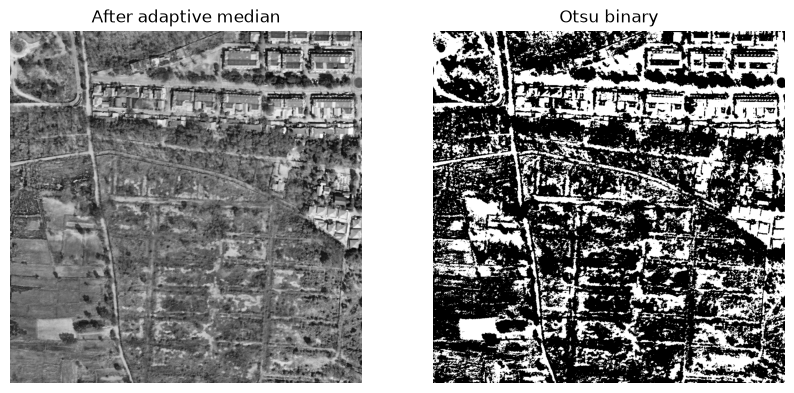

In [7]:
# Ref: otsu_thresholding_HW3
# partial reference from https://docs.opencv.org/4.13.0/d7/d4d/tutorial_py_thresholding.html
def dip_otsu_threshold(img):
    blur = cv2.GaussianBlur(img, (5, 5), 0)
 
    # find normalized_histogram, and its cumulative distribution function
    hist = cv2.calcHist([blur], [0], None, [256], [0, 256])
    hist_norm = hist.ravel() / hist.sum()
    Q = hist_norm.cumsum()
 
    bins = np.arange(256)
 
    fn_min = np.inf
    thresh = -1

    # change rest of implementation to a recursive method to find between class variance following Lec05_OtsuThreshold.pdf
    P = hist_norm
    mu = float((bins * P).sum())

    # added out of concern for python heap limit. Ordinarily I would look for ways to substitute the recursion with some np
    # to leverage the numpy speedup.
    q1_memo = np.full(256, np.nan)
    mu1_memo = np.full(256, np.nan)
 
    def q1(t):
        # ran into some issues with values going out of bounds, this is a quick fix to discart histogram values 
        if (not np.isnan(q1_memo[t])):
            return q1_memo[t]
        if (t == 0):
            q1_memo[t] = P[0]
            return q1_memo[t]
            
        q1_memo[t] = q1(t - 1) + P[t]
        return q1_memo[t]

    def mu1(t):
        if (not np.isnan(mu1_memo[t])):
            return mu1_memo[t]
        if (t == 0):
            mu1_memo[t] = 0.0
            return mu1_memo[t]
        denom = q1(t)
        if (denom == 0.0):
            mu1_memo[t] = 0.0
            return mu1_memo[t]
            
        mu1_memo[t] = (q1(t - 1) * mu1(t - 1) + t * P[t]) / denom
        return mu1_memo[t]

    def mu2(t):
        q = q1(t)
        if (q >= 1.0):
            return 0.0
        return (mu - q * mu1(t)) / (1.0 - q)
 
    max_between_variance = -np.inf
    for t in bins:
        q = q1(t)
        if (q <= 0.0 or q >= 1.0):
            continue
 
        # between_class_variance(t) = q1(t)[1 - q1(t)][mu1(t) - mu2(t)]^2
        between_variance = q * (1.0 - q) * (mu1(t) - mu2(t)) ** 2
 
        # find otsu's number
        if (between_variance > max_between_variance):
            max_between_variance = between_variance
            thresh = int(t)
            
    return thresh

otsu_value = dip_otsu_threshold(smoothed)
print("Otsu threshold:", otsu_value)

# > to < depending on the mask configuration
binary = np.where(smoothed > otsu_value, 255, 0).astype(np.uint8)

show([smoothed, binary], ["After adaptive median", "Otsu binary"])

## Morphological filtering
Opening removes specks that are too small to be roads.
Closing fills small holes and gaps inside road regions.

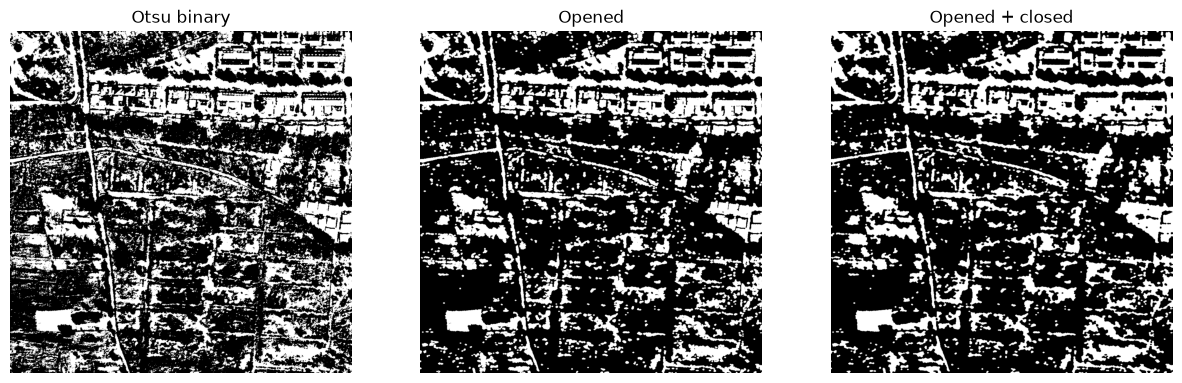

In [8]:
# https://docs.opencv.org/4.13.0/d9/d61/tutorial_py_morphological_ops.html
small_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, small_kernel)
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, small_kernel)

show([binary, opened, cleaned], ["Otsu binary", "Opened", "Opened + closed"])

## Morphological reconstruction
strong erosion would remove the leftover blobs, but it would also break the roads apart

- seed = the cleaned image after a strong erosion, where only the thick road centers remain
- mask = the cleaned image with full road shapes

Reconstruction by dilation would grow the seed back out to restore any remaining road centers

see below for reconstruction parameters and explenation.

https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.reconstruction

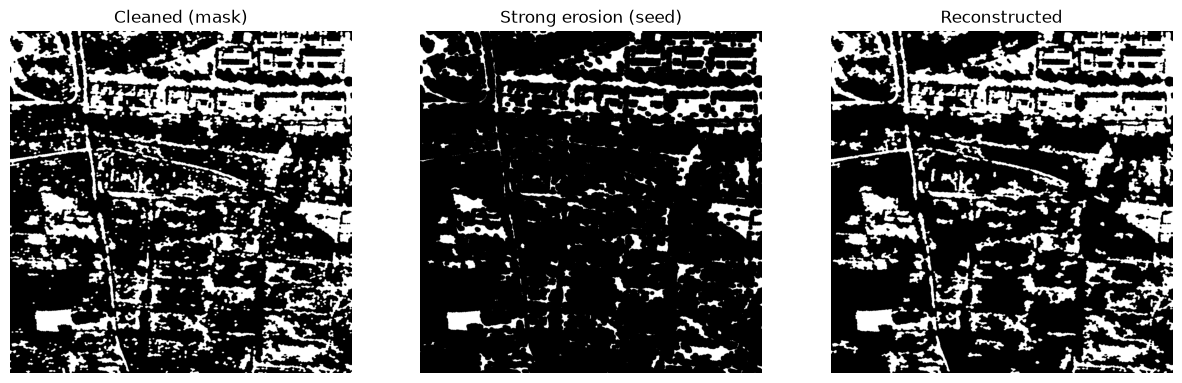

In [9]:
big_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
eroded = cv2.erode(cleaned, big_kernel)

seed = eroded > 0
mask = cleaned > 0

reconstructed = reconstruction(seed, mask, method="dilation")
predicted = reconstructed > 0

show([cleaned, eroded, predicted], ["Cleaned (mask)", "Strong erosion (seed)", "Reconstructed"])

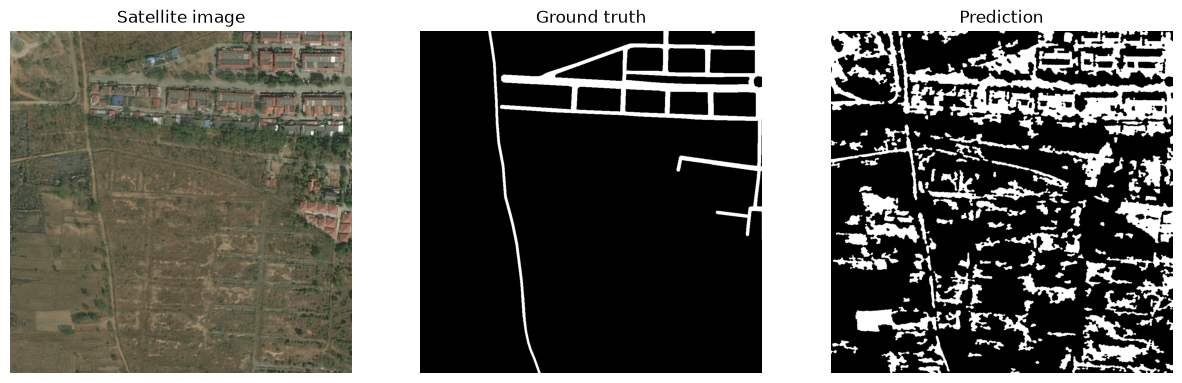

In [10]:
show([rgb, ground_truth, predicted],["Satellite image", "Ground truth", "Prediction"])